# 15 · System identification

Models come from physics or from data, and usually from both: the structure from physics, the numbers from
experiments. This notebook identifies the course's DC motor from its measured step response and from a
pseudo-random binary excitation, in time and in frequency domain. It shows the two-point FOPDT fit and a
second-order fit, then the ARX least-squares model and its failure mode - bias from output noise, amplified by
fast sampling - and the two remedies: a slower identification rate and the output-error fit on the simulation
error. The residuals' whiteness and a frequency-response fit close the chapter.

**What you will learn**
- fit FOPDT and second-order models to step responses and know their limits
- estimate ARX models by least squares and recognise the bias from output noise and fast sampling
- use the output-error method and residual whiteness
- fit a rational model to measured frequency-response data

**Before you start:** notebooks 01, 02 and 12  ·  **Time:** about 90 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, identify as idf, design as dg, discrete as dc, response as rs, frequency as fr, datasets, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Step-response data: cleaning and fitting

1500 samples at 1 kHz; 1 dropped sample(s) -> interpolated
FOPDT fit: K = 4.014 rad/s/V, tau = 0.315 s, L = 0.049 s    (true dc gain 4.000, poles [-19.25  -3.25])
second-order fit: K = 4.014, zeta = 0.720, wn = 3.877 - a plant with two real poles has been given a complex pair: the noise peak above the final value was read as an overshoot


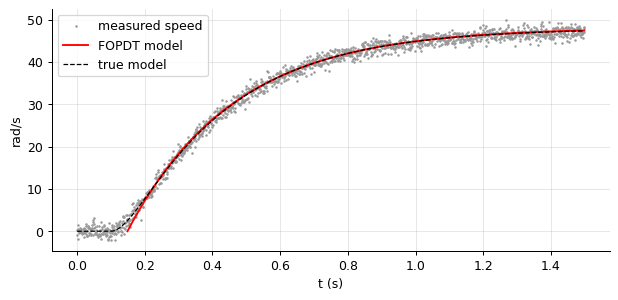

In [2]:
d = pd.read_csv(datasets.path("motor_step.csv"), comment="#")
print(f"{len(d)} samples at 1 kHz; {d.speed_rad_s.isna().sum()} dropped sample(s) -> interpolated")
d["speed_rad_s"] = d.speed_rad_s.interpolate()
t, V, y = d.t_s.to_numpy(), d.V.to_numpy(), d.speed_rad_s.to_numpy()
on = t >= 0.1
fo = dg.fopdt_from_step(t[on] - 0.1, y[on], u_amplitude=12.0)
so = idf.fit_second_order_step(t[on] - 0.1, y[on], u_amplitude=12.0)
true = models.dc_motor(R=2.0, L=0.1, Kt=0.05, Ke=0.05, J=0.002, b=0.005)["system"]
print(f"FOPDT fit: K = {fo['K']:.3f} rad/s/V, tau = {fo['tau']:.3f} s, L = {fo['L']:.3f} s    (true dc gain {true.dcgain()[0, 0]:.3f}, poles {np.round(true.poles().real, 2)})")
print(f"second-order fit: K = {so['K']:.3f}, zeta = {so['zeta']:.3f}, wn = {so['wn']:.3f} - a plant with two real poles has been given a complex pair: the noise peak above the final value was read as an overshoot")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t, y, ".", ms=2, color="0.6", label="measured speed")
tt = t[on] - 0.1
Pf = sy.tf([fo["K"]], [fo["tau"], 1.0])
tf_, yf = rs.step(Pf, tt[-1] - fo["L"], int(np.sum(tt >= fo["L"])))
ax.plot(0.1 + fo["L"] + tf_, 12 * yf, "r", label="FOPDT model"); ax.plot(t, 12 * rs.lsim(true, V / 12.0, t)[1], "k--", lw=1, label="true model"); ax.legend(); ax.set_xlabel("t (s)"); ax.set_ylabel("rad/s"); plt.show()

A dropped sample is interpolated; the two-point method then returns a gain within a percent of the truth and
a time constant close to the motor's slow pole, with the fast electrical pole absorbed into an apparent delay
of a few milliseconds. A step response gives the gain and the dominant time constant reliably and little
else; the second-order fit does worse than fail - it reads the noise peak above the final value as an
overshoot and returns ζ = 0.72, a complex pole pair for a plant whose poles are real. A fit that returns a
plausible number is not evidence that its model structure is right. For the fast dynamics one needs a richer
excitation.

## PRBS data and ARX least squares

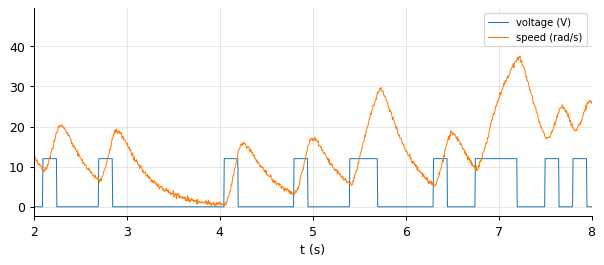

   dt         ARX poles       true poles  dc gain  fit %  std err of a
0.005 [-0.3481, 0.9933] [0.9082, 0.9839]    5.913 96.073         0.011
0.020  [0.2212, 0.9593] [0.6804, 0.9371]    4.644 95.061         0.018
0.050  [0.2825, 0.8626] [0.3819, 0.8502]    4.074 95.617         0.013


In [3]:
p = pd.read_csv(datasets.path("motor_prbs.csv"), comment="#")
p = p[p.t_s >= 2.0]                                                   # drop the start-up transient (the record begins at rest)
u = (p.V - p.V.mean()).to_numpy(); yv = (p.speed_rad_s - p.speed_rad_s.mean()).to_numpy()
dt = 0.005
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(p.t_s, p.V, lw=0.8, label="voltage (V)"); ax.plot(p.t_s, p.speed_rad_s, lw=0.8, label="speed (rad/s)"); ax.set_xlim(2, 8); ax.legend(fontsize=8); ax.set_xlabel("t (s)"); plt.show()
rows = []
for dec in (1, 4, 10):
    m = idf.arx(u[::dec], yv[::dec], 2, 2, 1, dt=dt * dec)
    true_z = np.sort(np.exp(true.poles().real * dt * dec))
    rows.append((dt * dec, np.round(np.sort(m["tf"].poles().real), 4).tolist(), np.round(true_z, 4).tolist(), m["tf"].dcgain(), m["fit_percent"], np.max(m["std_errors"][:2])))
print(pd.DataFrame(rows, columns=["dt", "ARX poles", "true poles", "dc gain", "fit %", "std err of a"]).to_string(index=False, float_format="%.3f"))

Least squares on the ARX regression is exact for noise-free data and fast to compute, and at the full 200 Hz
it is badly wrong: the two lagged outputs are almost collinear when the poles sit near z = 1, the b
coefficients are tiny, and the tachometer noise - 0.3 rad/s on a 47 rad/s swing - biases the estimate by far
more than its own standard error admits (0.004, against an error of 0.5 in a pole). Decimating to 20 Hz
spreads the poles and the estimate becomes usable. The fit percentage is no guide: it measures one-step
prediction, which any model with the right recent outputs does well.

## The output-error fit, and residual analysis

output-error model at 20 Hz: poles [0.3889 0.8494] (true [0.3819 0.8502]), dc gain 4.011 (true 4.000), simulation fit 90.9 %


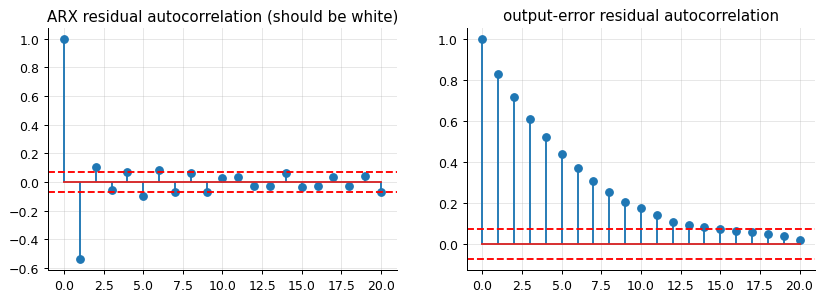

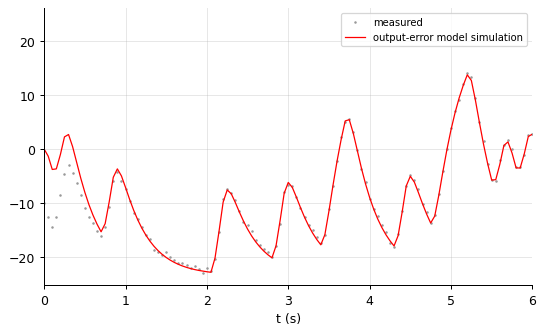

In [4]:
oe = idf.output_error(u[::10], yv[::10], 2, dt * 10)
Gc = oe["tf"]
print(f"output-error model at 20 Hz: poles {np.round(np.sort(Gc.poles().real), 4)} (true {np.round(np.sort(np.exp(true.poles().real * 0.05)), 4)}), dc gain {Gc.dcgain():.3f} (true 4.000), simulation fit {oe['fit_percent']:.1f} %")
ls10 = idf.arx(u[::10], yv[::10], 2, 2, 1, dt=0.05)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
lags = np.arange(21)
axes[0].stem(lags, idf.autocorrelation(ls10["residuals"], 20)); axes[0].axhline(2 / np.sqrt(len(ls10["residuals"])), color="r", ls="--"); axes[0].axhline(-2 / np.sqrt(len(ls10["residuals"])), color="r", ls="--"); axes[0].set_title("ARX residual autocorrelation (should be white)")
axes[1].stem(lags, idf.autocorrelation(oe["residuals"], 20)); axes[1].axhline(2 / np.sqrt(len(oe["residuals"])), color="r", ls="--"); axes[1].axhline(-2 / np.sqrt(len(oe["residuals"])), color="r", ls="--"); axes[1].set_title("output-error residual autocorrelation")
plt.show()
t20 = np.arange(len(yv[::10])) * 0.05
_, y_sim, _ = rs.lsim(Gc, u[::10])
plt.plot(t20, yv[::10], ".", ms=2, color="0.6", label="measured"); plt.plot(t20, y_sim, "r", lw=1, label="output-error model simulation"); plt.xlim(0, 6); plt.legend(fontsize=8); plt.xlabel("t (s)"); plt.show()

The output-error estimator minimises the error of the *simulated* output, so the noisy measurements never
enter a regressor and the estimate is unbiased: both poles and the gain come back within a percent of the
truth. The price is a nonlinear least-squares problem (Levenberg-Marquardt, started from the ARX estimate).
The residual autocorrelations tell the two stories: the ARX residual is coloured, the signature of a noise
model that does not match the data, while the output-error residual is close to white. Whiteness of the
residuals is the test that nothing systematic has been left unmodelled.

## Frequency-domain identification

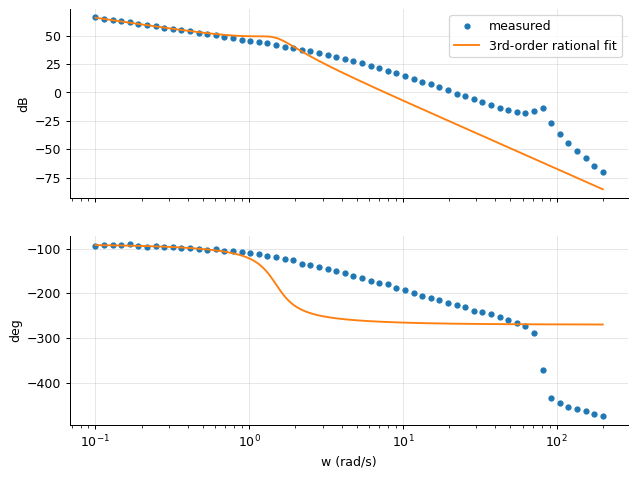

fitted model: TransferFunction(430.4 / s^3 + 0.7684s^2 + 2.231s - 0.001334) 
poles [-0.384+1.443j -0.384-1.443j  0.001+0.j   ]
the fit finds the integrator (a pole near 0) but turns the motor's two real poles into a complex pair: the resonance and the delay in the data, absent from the model, pull the fit - the project's problem


In [5]:
s_ = pd.read_csv(datasets.path("servo_frequency_response.csv"), comment="#")
w = s_.w_rad_s.to_numpy(); H = 10 ** (s_.gain_dB.to_numpy() / 20) * np.exp(1j * np.radians(s_.phase_deg.to_numpy()))
fit = idf.fit_frequency_response(w, H, 0, 3)
w_fine = np.logspace(-1, 2.3, 400)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].semilogx(w, s_.gain_dB, "o", ms=4, label="measured"); axes[0].semilogx(w_fine, 20 * np.log10(np.abs(fr.freqresp(fit, w_fine))), label="3rd-order rational fit"); axes[0].set_ylabel("dB"); axes[0].legend()
axes[1].semilogx(w, s_.phase_deg, "o", ms=4); axes[1].semilogx(w_fine, np.degrees(np.unwrap(np.angle(fr.freqresp(fit, w_fine)))), label="fit"); axes[1].set_ylabel("deg"); axes[1].set_xlabel("w (rad/s)")
plt.show()
print("fitted model:", fit, "\npoles", np.round(fit.poles(), 3))
print("the fit finds the integrator (a pole near 0) but turns the motor's two real poles into a complex pair: the resonance and the delay in the data, absent from the model, pull the fit - the project's problem")

A measured frequency response (a sine sweep on the servo) can be fitted directly by a rational function:
Levy's linearised least squares, reweighted by the previous denominator (Sanathanan-Koerner) to undo its
high-frequency bias. A third-order fit recovers the integrator but not the motor's two real poles: the data
contain a resonance and a delay that the model structure cannot represent, and the least-squares fit
compensates by placing a complex pole pair where none exists. The lesson is the same as the step's: structure
first, then numbers. The project takes the resonance and the delay into the model explicitly.

## Inside the algorithm: the ARX regression matrix

In [6]:
na, nb, nk = 2, 2, 1
yy, uu = yv[::10], u[::10]
k0 = max(na, nb + nk - 1)
Phi = np.array([np.r_[-yy[k - na:k][::-1], uu[k - nk - nb + 1:k - nk + 1][::-1]] for k in range(k0, len(yy))])
theta = np.linalg.lstsq(Phi, yy[k0:], rcond=None)[0]
print("regression by hand: a =", np.round(theta[:na], 5), "b =", np.round(theta[na:], 5), " library:", np.round(ls10["a"], 5), np.round(ls10["b"], 5))

regression by hand: a = [-1.14515  0.24373] b = [0.21341 0.18821]  library: [-1.14515  0.24373] [0.21341 0.18821]


## Exercises
1. Repeat the ARX fit at 200 Hz with the instrumental-variable option (`identify.arx(..., method='iv')`) and with the record truncated to 10 s and 40 s. Does IV remove the bias, and how does its variance compare with the output-error fit?
2. Fit the servo frequency response with orders (0, 3), (2, 5) and (2, 6) and compare the fits around the resonance; then add a Pade(2) delay factor to the model and fit again. Which model would you use for design, and why not the one with the best fit?
3. **Implement it yourself:** write the output-error cost (sum of squared simulation errors) as a function of the two poles and the gain of a first-order-plus-gain discrete model and minimise it with `scipy.optimize.minimize` on the PRBS data at 20 Hz; compare with `identify.output_error`.